# Establish how many students and employees are impacted by each water filling station

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Change the path
df_density_map = pd.read_csv(r'D:\study\506\updated_densitymap_hourly_cleaned.csv')
df_bottle_fillers = pd.read_csv(r'D:\study\506\bottle_fillers_inventory.csv')
df_public_kitchens = pd.read_csv(r'D:\study\506\public_kitchens.csv')
df_bottle_fillers_head = df_bottle_fillers.head()
df_density_map_head = df_density_map.head()
df_bottle_fillers_head, df_density_map_head

(  Address A          Address B    Floor   \
 0       100         Ashford St     First   
 1       120         Ashford St     First   
 2       120         Ashford St    Second   
 3         8  St. Mary's Street  Basement   
 4         8  St. Mary's Street     First   
 
                                          Description Accessibility  \
 0  Hallway across from vending machines, across f...        Public   
 1                             Kitchenette, Room 116A    Restricted   
 2                              Kitchenette, Room 222    Restricted   
 3                               Hallway by bathrooms           NaN   
 4                         Hallway by electrical room           NaN   
 
   Handicap Accessible Space@Bu room  Quantity Date Installed  \
 0                 Yes           191         1            NaN   
 1                 Yes          116A         1            NaN   
 2                 Yes           222         1            NaN   
 3                 NaN           B81    

Normalize and match addresses in updated_densitymap_hourly_cleaned.csv and Bottle Fillers Inventory - ongoing.csv. Print the Normalized address of Bottle Fillers Inventory - ongoing.csv.

In [2]:
# write the normalize_address function
def normalize_address(address):
    if pd.isnull(address):
        return None
    address = address.upper().strip()  
    suffixes = {'STREET': 'ST', 'AVENUE': 'AVE', 'BOULEVARD': 'BLVD', 'ROAD': 'RD', 'DRIVE': 'DR'}
    for long, short in suffixes.items():
        address = address.replace(long, short)
    # Remove all non-alphanumeric characters (except spaces and periods)
    address = ''.join(char for char in address if char.isalnum() or char in ' .')
    return address

# Define manual matching rules
manual_matches = {
    '8 ST MARYS ST': '8 ST. MARY\'S ST',
    '156 BAY STATE RD': '156 BAY STATE RD',
    
    #-------------Unmatched addresses-----------------
    '264 BAY STATE RD': '264270 BAY STATE RD',
    '270 BAY STATE RD': '264270 BAY STATE RD',
    '517 BEACON ST': '517521 BEACON ST',
    '621 COMMONWEALTH AVE': '617621 COMMONWEALTH AVE',
    '675 COMMONWEALTH AVE': '675  725 COMMONWEALTH AVE',
    '685 COMMONWEALTH AVE': '675  725 COMMONWEALTH AVE',
    '705 COMMONWEALTH AVE': '675  725 COMMONWEALTH AVE',
    '725 COMMONWEALTH AVE': '675  725 COMMONWEALTH AVE',
    '745 COMMONWEALTH AVE': '745  755 COMMONWEALTH AVE',
    '5 CUMMINGTON MALL': '3  5 CUMMINGTON MALL',
    '36 CUMMINGTON MALL': '3038 CUMMINGTON MALL',
    '48 CUMMINGTON MALL': '4852 CUMMINGTON MALL',
    '64 CUMMINGTON MALL': '6486 CUMMINGTON MALL',
    '68 CUMMINGTON MALL': '6486 CUMMINGTON MALL',
    '96 CUMMINGTON MALL': '96100 CUMMINGTON MALL',
}

# Apply manual matching rules
def apply_manual_matches(address):
    return manual_matches.get(address, address)

# Apply normalization to address columns
df_bottle_fillers['Normalized Address A'] = df_bottle_fillers['Address A'].astype(str).apply(normalize_address)
df_bottle_fillers['Normalized Address B'] = df_bottle_fillers['Address B'].astype(str).apply(normalize_address)
df_public_kitchens['Normalized Address'] = df_public_kitchens['Building Description (BLDGDESC)'].astype(str).apply(normalize_address)
df_density_map['Normalized building_desc'] = df_density_map['building_desc'].astype(str).apply(normalize_address)

# Apply manual matching rules
#df_bottle_fillers['Manual Matched Address A'] = df_bottle_fillers['Normalized Address A'].apply(apply_manual_matches)
#df_bottle_fillers['Manual Matched Address B'] = df_bottle_fillers['Normalized Address B'].apply(apply_manual_matches)
df_public_kitchens['Manual Matched Address'] = df_public_kitchens['Normalized Address'].apply(apply_manual_matches)

#prepare and merge
df_public_kitchens.rename(columns={'Public Kitchen': 'Quantity'}, inplace=True)
df_public_kitchens_for_merge = df_public_kitchens[['Manual Matched Address', 'Quantity']].rename(columns={'Manual Matched Address': 'Full Manual Matched Address'})


df_bottle_fillers['Full Manual Matched Address'] = df_bottle_fillers['Normalized Address A'] + ' ' + df_bottle_fillers['Normalized Address B'].fillna('')
df_bottle_fillers['Full Manual Matched Address'] = df_bottle_fillers['Full Manual Matched Address'].apply(apply_manual_matches)
df_bottle_fillers = pd.concat([df_bottle_fillers, df_public_kitchens_for_merge], ignore_index=True)

#matching
normalized_building_desc_set = set(df_density_map['Normalized building_desc'])

df_bottle_fillers['Is Matched'] = df_bottle_fillers['Full Manual Matched Address'].apply(lambda x: x in normalized_building_desc_set)

matched_addresses_in_bottle_fillers = df_bottle_fillers[df_bottle_fillers['Is Matched']]
print(matched_addresses_in_bottle_fillers[['Address A', 'Address B', 'Full Manual Matched Address']])



    Address A          Address B Full Manual Matched Address
0         100         Ashford St              100 ASHFORD ST
1         120         Ashford St              120 ASHFORD ST
2         120         Ashford St              120 ASHFORD ST
3           8  St. Mary's Street              8 ST. MARYS ST
4           8  St. Mary's Street              8 ST. MARYS ST
..        ...                ...                         ...
443       NaN                NaN            124 BAY STATE RD
444       NaN                NaN            161 BAY STATE RD
445       NaN                NaN            163 BAY STATE RD
446       NaN                NaN            163 BAY STATE RD
447       NaN                NaN              275 BABCOCK ST

[366 rows x 3 columns]


In [3]:
bottle_filler_addresses_set = set(df_bottle_fillers['Full Manual Matched Address'])

df_density_map['Is Matched'] = df_density_map['Normalized building_desc'].apply(lambda x: x in bottle_filler_addresses_set)


Print the successfully matched addresses in the two tables.

In [4]:
matched_df = pd.merge(
    df_bottle_fillers,
    df_density_map,
    left_on='Full Manual Matched Address',
    right_on='Normalized building_desc',
    how='inner'  
)

print(matched_df[['Full Manual Matched Address', 'building_desc']])


         Full Manual Matched Address       building_desc
0                     100 ASHFORD ST  100 ASHFORD STREET
1                     100 ASHFORD ST  100 ASHFORD STREET
2                     100 ASHFORD ST  100 ASHFORD STREET
3                     100 ASHFORD ST  100 ASHFORD STREET
4                     100 ASHFORD ST  100 ASHFORD STREET
...                              ...                 ...
38963077              275 BABCOCK ST  275 BABCOCK STREET
38963078              275 BABCOCK ST  275 BABCOCK STREET
38963079              275 BABCOCK ST  275 BABCOCK STREET
38963080              275 BABCOCK ST  275 BABCOCK STREET
38963081              275 BABCOCK ST  275 BABCOCK STREET

[38963082 rows x 2 columns]


In [5]:

normalized_building_desc_set = set(df_density_map['Normalized building_desc'])


matched_addresses_in_bottle_fillers = df_bottle_fillers[df_bottle_fillers['Is Matched']]
matched_addresses = matched_addresses_in_bottle_fillers[['Address A', 'Address B', 'Full Manual Matched Address']]
matched_addresses


,Address A,Address B,Full Manual Matched Address
0,100,Ashford St,100 ASHFORD ST
1,120,Ashford St,120 ASHFORD ST
2,120,Ashford St,120 ASHFORD ST
3,8,St. Mary's Street,8 ST. MARYS ST
4,8,St. Mary's Street,8 ST. MARYS ST
...,...,...,...
443,NaN,NaN,124 BAY STATE RD
444,NaN,NaN,161 BAY STATE RD
445,NaN,NaN,163 BAY STATE RD
446,NaN,NaN,163 BAY STATE RD


Display unmatched addresses in Bottle Fillers Inventory and public kitchens.

In [6]:
# Create a set of all normalized building descriptions from the density map for checking matches
normalized_building_desc_set = set(df_density_map['Normalized building_desc'])

# Filter out and display unmatched addresses
unmatched_addresses_in_bottle_fillers = df_bottle_fillers[~df_bottle_fillers['Is Matched']]
unmatched_addresses = unmatched_addresses_in_bottle_fillers[['Address A', 'Address B', 'Full Manual Matched Address']]

unmatched_addresses

,Address A,Address B,Full Manual Matched Address
175,767,Commonwealth Ave,767 COMMONWEALTH AVE
176,767,Commonwealth Ave,767 COMMONWEALTH AVE
265,NaN,NaN,183 BAY STATE RD
266,NaN,NaN,183 BAY STATE RD
273,NaN,NaN,69 BAY STATE RD
...,...,...,...
450,NaN,NaN,71 BAY STATE RD
451,NaN,NaN,71 BAY STATE RD
452,NaN,NaN,71 BAY STATE RD
453,NaN,NaN,71 BAY STATE RD


Calculate the sum of daily foot traffic for each location. If a location has multiple water stations, divide the sum of foot traffic by the number of water stations.

C:\Users\guoqi\AppData\Local\Temp\ipykernel_30168\1485637834.py:67: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  average_density_adjusted['Filler Counts'].replace(0, 1, inplace=True)  # Replace 0 with 1 for calculation


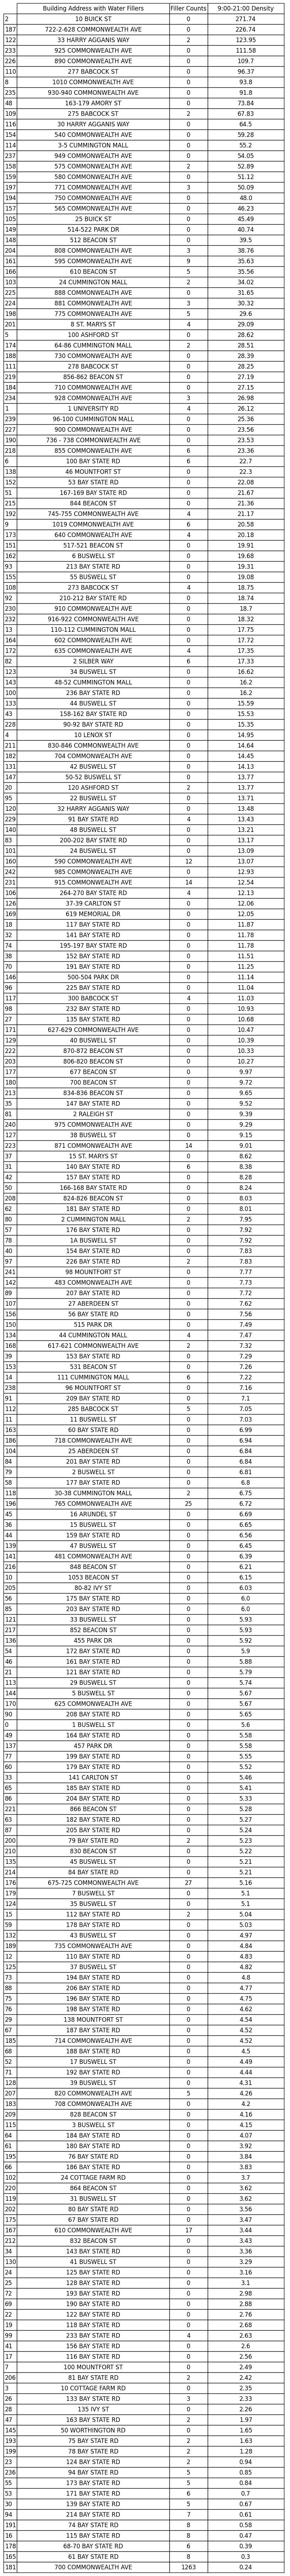

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from pandas.plotting import table


# Address replacement dictionary
address_replacement = {
    '6486 CUMMINGTON MALL': '64-86 CUMMINGTON MALL',
    '264270 BAY STATE RD': '264-270 BAY STATE RD',
    '517521 BEACON ST': '517-521 BEACON ST',
    '617621 COMMONWEALTH AVE': '617-621 COMMONWEALTH AVE',
    '675  725 COMMONWEALTH AVE': '675-725 COMMONWEALTH AVE',
    '745  755 COMMONWEALTH AVE': '745-755 COMMONWEALTH AVE',
    '3  5 CUMMINGTON MALL': '3-5 CUMMINGTON MALL',
    '3038 CUMMINGTON MALL': '30-38 CUMMINGTON MALL',
    '4852 CUMMINGTON MALL': '48-52 CUMMINGTON MALL',
    '96100 CUMMINGTON MALL': '96-100 CUMMINGTON MALL',
    '110112 CUMMINGTON MALL': '110-112 CUMMINGTON MALL',
    '7222628 COMMONWEALTH AVE':'722-2-628 COMMONWEALTH AVE',
    '930940 COMMONWEALTH AVE':'930-940 COMMONWEALTH AVE',
    '163179 AMORY ST':'163-179 AMORY ST',
    '514522 PARK DR':'514-522 PARK DR',
    '856862 BEACON ST':'856-862 BEACON ST',
    '736  738 COMMONWEALTH AVE':'736 - 738 COMMONWEALTH AVE',
    '167169 BAY STATE RD':'167-169 BAY STATE RD',
    '210212 BAY STATE RD':'210-212 BAY STATE RD',
    '916922 COMMONWEALTH AVE':'916-922 COMMONWEALTH AVE',
    '158162 BAY STATE RD':'158-162 BAY STATE RD',
    '9092 BAY STATE RD':'90-92 BAY STATE RD',
    '830846 COMMONWEALTH AVE':'830-846 COMMONWEALTH AVE',
    '5052 BUSWELL ST':'50-52 BUSWELL ST',
    '200202 BAY STATE RD':'200-202 BAY STATE RD',
    '3739 CARLTON ST':'37-39 CARLTON ST',
    '195197 BAY STATE RD':'195-197 BAY STATE RD',
    '500504 PARK DR':'500-504 PARK DR',
    '627629 COMMONWEALTH AVE':'627-629 COMMONWEALTH AVE',
    '870872 BEACON ST':'870-872 BEACON ST',
    '806820 BEACON ST':'806-820 BEACON ST',
    '834836 BEACON ST':'834-836 BEACON ST',
    '166168 BAY STATE RD':'166-168 BAY STATE RD',
    '824826 BEACON ST':'824-826 BEACON ST',
    '8082 IVY ST':'80-82 IVY ST',
    '6870 BAY STATE RD':'68-70 BAY STATE RD',
}

# Filter density map for relevant hours and calculate mean density
df_density_map_filtered = df_density_map[(df_density_map['hour'] >= 9) & (df_density_map['hour'] <= 21)]
df_density_map_grouped = df_density_map_filtered.groupby(['Normalized building_desc', 'date', 'hour'])['density_cnt'].sum().reset_index()
average_density_per_address = df_density_map_grouped.groupby('Normalized building_desc')['density_cnt'].mean().reset_index()

# Calculate filler quantity
address_counts = df_bottle_fillers.groupby('Full Manual Matched Address')['Quantity'].sum().reset_index()
address_counts.columns = ['Full Manual Matched Address', 'Filler Counts']

# Handle unmatched addresses
unmatched_density_map_addresses = df_density_map[~df_density_map['Normalized building_desc'].isin(address_counts['Full Manual Matched Address'])]['Normalized building_desc'].unique()
df_unmatched_addresses = pd.DataFrame({
    'Full Manual Matched Address': unmatched_density_map_addresses,
    'Filler Counts': [0] * len(unmatched_density_map_addresses)
})

# Combine matched and unmatched addresses
df_combined = pd.concat([address_counts, df_unmatched_addresses], ignore_index=True)

# Adjust density per filler, avoiding division by zero
average_density_adjusted = pd.merge(average_density_per_address, df_combined, left_on='Normalized building_desc', right_on='Full Manual Matched Address', how='left')
average_density_adjusted['Filler Counts'].replace(0, 1, inplace=True)  # Replace 0 with 1 for calculation
average_density_adjusted['9:00-21:00 Density'] = average_density_adjusted['density_cnt'] / average_density_adjusted['Filler Counts']

# Restore original Filler Counts for display (including 0s)
average_density_adjusted['Filler Counts'] = average_density_adjusted['Filler Counts'].replace(1, 0)

# Sort and round the final data
average_density_adjusted_sorted = average_density_adjusted.sort_values(by='9:00-21:00 Density', ascending=False)
average_density_adjusted_sorted['9:00-21:00 Density'] = average_density_adjusted_sorted['9:00-21:00 Density'].round(2)

# Apply address replacement for display
average_density_adjusted_sorted['Normalized building_desc'] = average_density_adjusted_sorted['Normalized building_desc'].map(lambda x: address_replacement.get(x, x))
average_density_adjusted_sorted.rename(columns={'Normalized building_desc': 'Building Address with Water Fillers'}, inplace=True)

# Prepare the display DataFrame
df_display = average_density_adjusted_sorted[['Building Address with Water Fillers', 'Filler Counts', '9:00-21:00 Density']]

# Display the table in a matplotlib figure
fig, ax = plt.subplots(figsize=(10, len(df_display) * 0.3))
ax.axis('off')
tbl = table(ax, df_display, loc='center', cellLoc='center', colWidths=[0.4, 0.1, 0.2])
tbl.auto_set_font_size(False)
tbl.set_fontsize(12)
tbl.scale(1.4, 1.8)
plt.savefig('adjusted_density_and_filler_count_display.png', bbox_inches='tight', dpi=200)



In [8]:
pd.set_option('display.max_rows', None)

print(df_display)

pd.set_option('display.max_rows', 10)

    Building Address with Water Fillers  Filler Counts  9:00-21:00 Density
2                           10 BUICK ST              0              271.74
187          722-2-628 COMMONWEALTH AVE              0              226.74
122                33 HARRY AGGANIS WAY              2              123.95
233                925 COMMONWEALTH AVE              0              111.58
226                890 COMMONWEALTH AVE              0              109.70
110                      277 BABCOCK ST              0               96.37
8                 1010 COMMONWEALTH AVE              0               93.80
235            930-940 COMMONWEALTH AVE              0               91.80
48                     163-179 AMORY ST              0               73.84
109                      275 BABCOCK ST              2               67.83
116                30 HARRY AGGANIS WAY              0               64.50
154                540 COMMONWEALTH AVE              0               59.28
114                 3-5 C

In [9]:
pd.set_option('display.max_rows', None)

print(unmatched_addresses)

pd.set_option('display.max_rows', 10)


    Address A         Address B Full Manual Matched Address
175       767  Commonwealth Ave        767 COMMONWEALTH AVE
176       767  Commonwealth Ave        767 COMMONWEALTH AVE
265       NaN               NaN            183 BAY STATE RD
266       NaN               NaN            183 BAY STATE RD
273       NaN               NaN             69 BAY STATE RD
274       NaN               NaN             69 BAY STATE RD
275       NaN               NaN             69 BAY STATE RD
276       NaN               NaN             69 BAY STATE RD
277       NaN               NaN             69 BAY STATE RD
278       NaN               NaN             69 BAY STATE RD
279       NaN               NaN             69 BAY STATE RD
287       NaN               NaN             96 BAY STATE RD
288       NaN               NaN             96 BAY STATE RD
289       NaN               NaN             96 BAY STATE RD
290       NaN               NaN             96 BAY STATE RD
291       NaN               NaN         